# LBM D1Q3 quantique : changement de variables + LCU de deux unitaires

**Objectif.** Remplacer le block-encoding FABLE de la collision par un block-encoding **exact et de facteur 1**, obtenu en deux temps :
1. **changement de variables** $G^n=\mathcal W^{-1/2}F^n$, avec $\mathcal W=\mathrm{diag}(\omega)\otimes I_N$ : la collision devient une matrice symétrique de norme 1 ;
2. **LCU de deux unitaires** : $\hat C_{loc}=\tfrac{1+\lambda}{2}I+\tfrac{1-\lambda}{2}R$, avec $R$ une réflexion, implémentée par une réflexion de Householder (1 ancilla par pas).

Le tout est appliqué aux deux modèles :
- **diffusion** : $f^{eq}_a=\omega_a\rho$ ;
- **advection-diffusion** : $f^{eq}_a=\omega_a\rho\,(1+c_a u/c_s^2)$, avec $u=j/\rho$, soit $f^{eq}=E\,f$.

Le streaming est **le même** que dans `LBM_D1Q3_Circuit_tot.ipynb` (incréments contrôlés) : seule la collision change, ce qui isole l'effet de la méthode.

**Plan**
0. Notations et paramètres
1. Les deux modèles classiques
2. Le changement de variables
3. La collision par LCU (Householder)
4. Streaming et un pas complet
5. Circuit complet : calcul exact
6. Exécution avec des *shots*, comparaison avec FABLE
7. Tableau comparatif
8. Portée du résultat : qubits, portes, succès, lecture

Chaque affirmation est soit **démontrée** dans le texte, soit **vérifiée** par une assertion ou une sortie du code.

## 0. Notations et paramètres

Notations de `LBM_D1Q3_Circuit_tot.ipynb` :
- directions $a\in\{0,-,+\}$, poids $\omega=(2/3,\,1/6,\,1/6)$, vitesses $c=(0,-1,+1)$, $c_s^2=\sum_a\omega_ac_a^2=1/3$ ;
- $F^n=(f^n_0,f^n_-,f^n_+)\in\mathbb R^{3N}$, la composante $(a,i)$ est en position $a\cdot N+i$ ;
- $C=C_{loc}\otimes I_N$, $C_{loc}=(1-\tfrac1\tau)I_3+\tfrac1\tau E$, avec $E=\omega\mathbf 1^T$ en diffusion ;
- $S=\mathrm{diag}(I_N,P^-,P^+)$, $(P^+v)_i=v_{i-1}$, $P^-=(P^+)^T$ ; schéma $F^{n+1}=S\,C\,F^n$ ;
- version $4N$ : direction vide $\varnothing$, $S_4=\mathrm{diag}(I_N,P^-,P^+,I_N)$, $D=4N$ ;
- qubits : position sur $q_0..q_{k-1}$, direction sur $q_k,q_{k+1}$, avec $0\to|00\rangle$, $-\to|01\rangle$, $+\to|10\rangle$, $\varnothing\to|11\rangle$.

Nouvelles notations : $\lambda=1-\tfrac1\tau$, $\sqrt\omega=(\sqrt{\omega_0},\sqrt{\omega_-},\sqrt{\omega_+})^T$.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from fable import fable
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit.circuit.library import StatePreparation, UnitaryGate
from qiskit_aer import AerSimulator

np.set_printoptions(precision=4, suppress=True)

tau = 0.8                    # temps de relaxation
k = 3                        # qubits de position
N = 2**k                     # noeuds
D = 4*N                      # dimension apres ajout de la direction vide
T = 3                        # nombre de pas
w = np.array([2/3, 1/6, 1/6])          # ordre (0, -, +)
c = np.array([0, -1, +1])
cs2 = (w*c**2).sum(); cs = np.sqrt(cs2)
lam = 1 - 1/tau                         # lambda
sigma0 = 1.5                            # largeur de la gaussienne initiale
sq = np.sqrt(w)                         # sqrt(omega)

print(f"tau = {tau}, lambda = {lam}, N = {N}, T = {T}, c_s^2 = {cs2:.4f}")

tau = 0.8, lambda = -0.25, N = 8, T = 3, c_s^2 = 0.3333


## 1. Les deux modèles classiques

| | diffusion | advection-diffusion |
|---|---|---|
| matrice d'équilibre $E$ ($f^{eq}=Ef$ au nœud $i$) | $\omega\mathbf 1^T$ | $\omega\mathbf 1^T+\dfrac{(\omega\circ c)\,c^T}{c_s^2}$ |
| condition initiale | $\rho^0$ gaussienne, $j^0=0$ | $\rho^0=\bar\rho+\delta\rho^0$, $j^0=c_s\,\delta\rho^0$ (onde progressive) |
| fond $\bar\rho$ | $0$ | $1$ (nécessaire pour avoir $f\ge0$) |

Dans les deux cas $F^0=f^{eq}(\rho^0,j^0)$ (initialisation à l'équilibre). Le streaming et la boucle LBM sont ceux de `Circuit_tot`.

In [2]:
E_diff = np.outer(w, np.ones(3))
E_adv = E_diff + np.outer(w*c, c)/cs2

def modele(nom, k):
    # renvoie le modele (matrices locales + condition initiale) pour 2^k noeuds
    N_ = 2**k; x_ = np.arange(N_)
    g = np.exp(-(x_ - N_/2)**2/(2*sigma0**2))
    if nom == "diffusion":
        E, fond = E_diff, 0.0
        f0 = w[:, None]*g                                   # f^eq(rho0, 0)
    elif nom == "advection-diffusion":
        E, fond = E_adv, 1.0
        f0 = w[:, None]*(fond + g) + (w*c/cs2)[:, None]*(cs*g)   # f^eq(rho0, j0 = cs*drho0)
    else:
        raise ValueError(nom)
    C_loc = (1 - 1/tau)*np.eye(3) + E/tau
    return dict(nom=nom, k=k, N=N_, E=E, C_loc=C_loc, fond=fond, f0=f0)

def lbm_step(f, E):
    # collision BGK f <- f - (f - E f)/tau, puis streaming (f de forme (3, N))
    fs = f - (f - E @ f)/tau
    return np.stack([fs[0], np.roll(fs[1], -1), np.roll(fs[2], +1)])

def lbm(m, T_):
    f = m["f0"].copy(); traj = [f]
    for _ in range(T_):
        f = lbm_step(f, m["E"]); traj.append(f)
    return traj

modeles = [modele("diffusion", k), modele("advection-diffusion", k)]
for m in modeles:
    traj = lbm(m, T)
    m["f_T"] = traj[-1]
    m["rho_T"] = traj[-1].sum(axis=0)
    m["signal"] = m["rho_T"] - m["fond"]                  # grandeur physique utile
    fmin = min(f.min() for f in traj)
    assert np.allclose(m["C_loc"].sum(axis=0), 1)        # conservation de la masse
    assert fmin >= 0                                     # requis pour la lecture sqrt(P)
    print(f"{m['nom']:20s} C_loc =\n{m['C_loc']}\n  min f sur {T} pas = {fmin:.4f}, masse = {m['f0'].sum():.4f}\n")

diffusion            C_loc =
[[ 0.5833  0.8333  0.8333]
 [ 0.2083 -0.0417  0.2083]
 [ 0.2083  0.2083 -0.0417]]
  min f sur 3 pas = 0.0048, masse = 3.7229

advection-diffusion  C_loc =
[[ 0.5833  0.8333  0.8333]
 [ 0.2083  0.5833 -0.4167]
 [ 0.2083 -0.4167  0.5833]]
  min f sur 3 pas = 0.0447, masse = 11.7229



## 2. Le changement de variables $G=\mathcal W^{-1/2}F$

**Définition.** $W=\mathrm{diag}(\omega)$, $\mathcal W=W\otimes I_N=\mathrm{diag}(\omega_0I_N,\omega_-I_N,\omega_+I_N)$, et
$$G^n=\mathcal W^{-1/2}F^n,\qquad\text{c'est-à-dire}\qquad g^n_{a,i}=f^n_{a,i}/\sqrt{\omega_a}.$$
En multipliant à gauche par $\mathcal W^{1/2}$ (possible car tous les $\omega_a>0$) : $F^n=\mathcal W^{1/2}G^n$.

**Nouvelle récurrence (démontrée).**
$$G^{n+1}=\mathcal W^{-1/2}F^{n+1}=\mathcal W^{-1/2}S\,C\,F^n=\mathcal W^{-1/2}S\,C\,\mathcal W^{1/2}G^n .$$
$S$ et $\mathcal W^{-1/2}$ sont diagonales par blocs (même découpage), et les blocs de $\mathcal W^{-1/2}$ sont des multiples de $I_N$, donc ils commutent : $\mathcal W^{-1/2}S=S\,\mathcal W^{-1/2}$. D'où
$$G^{n+1}=S\,\hat C\,G^n,\qquad \hat C=\mathcal W^{-1/2}C\,\mathcal W^{1/2}=\hat C_{loc}\otimes I_N,\qquad \hat C_{loc}=W^{-1/2}C_{loc}W^{1/2}.$$
**Le streaming ne change pas** ; seule la collision locale change.

**Structure de $\hat C_{loc}$ (démontrée).** $\hat C_{loc}=\lambda I_3+(1-\lambda)\Pi$, avec $\Pi=W^{-1/2}EW^{1/2}$ :
- diffusion : $\Pi=\sqrt\omega\sqrt\omega^T$, projecteur orthogonal de rang 1, car $\sqrt\omega^T\sqrt\omega=\sum_a\omega_a=1$ ;
- advection : $\Pi=\sqrt\omega\sqrt\omega^T+\frac{(\sqrt\omega\circ c)(\sqrt\omega\circ c)^T}{c_s^2}$, projecteur orthogonal de rang 2, car $\sqrt\omega\perp\sqrt\omega\circ c$ ($\sum\omega_ac_a=0$) et $\|\sqrt\omega\circ c\|^2=c_s^2$.

Donc $\hat C_{loc}=\Pi+\lambda(I-\Pi)$ est **symétrique**, de valeurs propres $1$ et $\lambda$, et $\|\hat C_{loc}\|_2=\max(1,|\lambda|)=1$ dès que $\tau\ge\frac12$.

La cellule suivante vérifie tout cela numériquement, ainsi que l'équivalence exacte $F^n=\mathcal W^{1/2}G^n$ pendant $T$ pas.

In [3]:
Wm = np.diag(1/sq); Wp = np.diag(sq)                    # W^{-1/2}, W^{1/2}
I_N = np.eye(N)
P_plus = np.roll(I_N, 1, axis=0); P_minus = P_plus.T; Z = np.zeros((N, N))
S = np.block([[I_N, Z, Z], [Z, P_minus, Z], [Z, Z, P_plus]])
calW_m = np.kron(Wm, I_N)                               # (W^{-1/2} (x) I_N)
print("W^{-1/2} S = S W^{-1/2} :", np.allclose(calW_m @ S, S @ calW_m))

for m in modeles:
    Pi = Wm @ m["E"] @ Wp
    C_hat = Wm @ m["C_loc"] @ Wp
    m["Pi"], m["C_hat"] = Pi, C_hat
    assert np.allclose(Pi, Pi.T) and np.allclose(Pi @ Pi, Pi)          # projecteur orthogonal
    assert np.allclose(C_hat, Pi + lam*(np.eye(3) - Pi))
    assert np.allclose(sq @ C_hat, sq)                                  # masse : sqrt(w)^T C_hat = sqrt(w)^T
    sv_C = np.linalg.svd(m["C_loc"], compute_uv=False); sv_Ch = np.linalg.svd(C_hat, compute_uv=False)
    ev_C = np.sort(np.linalg.eigvals(m["C_loc"]).real); ev_Ch = np.sort(np.linalg.eigvalsh(C_hat))
    # equivalence exacte des deux dynamiques sur T pas
    F = m["f0"].reshape(-1); G = calW_m @ F
    for _ in range(T):
        F = S @ np.kron(m["C_loc"], I_N) @ F
        G = S @ np.kron(C_hat, I_N) @ G
    ecart = np.abs(np.kron(Wp, I_N) @ G - F).max()
    print(f"--- {m['nom']}")
    print(f"  rang de Pi = {int(round(np.trace(Pi)))}")
    print(f"  valeurs propres  C_loc : {ev_C}   C_hat : {ev_Ch}   (identiques : matrices semblables)")
    print(f"  valeurs singul.  C_loc : {sv_C}   C_hat : {sv_Ch}")
    print(f"  max |W^(1/2) G^T - F^T| = {ecart:.1e}")

W^{-1/2} S = S W^{-1/2} : True
--- diffusion
  rang de Pi = 1
  valeurs propres  C_loc : [-0.25 -0.25  1.  ]   C_hat : [-0.25 -0.25  1.  ]   (identiques : matrices semblables)
  valeurs singul.  C_loc : [1.3451 0.25   0.1859]   C_hat : [1.   0.25 0.25]
  max |W^(1/2) G^T - F^T| = 2.2e-16
--- advection-diffusion
  rang de Pi = 2
  valeurs propres  C_loc : [-0.25  1.    1.  ]   C_hat : [-0.25  1.    1.  ]   (identiques : matrices semblables)
  valeurs singul.  C_loc : [1.3451 1.     0.1859]   C_hat : [1.   1.   0.25]
  max |W^(1/2) G^T - F^T| = 4.4e-16


**Lecture.** Les valeurs propres sont identiques (les deux matrices sont semblables), mais la **norme** passe de $1{,}345$ à $1$. C'est la norme, pas le spectre, qui fixe le facteur d'un block-encoding : un facteur 1 devient possible.

**Remarque importante.** Le changement de variables **seul** ne suffit pas : avec FABLE, le bloc encodé reste divisé par $4\alpha$ (normalisation par la dimension), donc le succès par pas reste $\le 1/16$. Il faut un block-encoding de facteur 1 : c'est l'objet de la partie 3.

## 3. La collision par LCU de deux unitaires

**Décomposition (démontrée).** Pour $\lambda\in[-1,1]$ :
$$\hat C_{loc}=\lambda I+(1-\lambda)\Pi=\underbrace{\tfrac{1+\lambda}{2}}_{a}\,I+\underbrace{\tfrac{1-\lambda}{2}}_{b}\,R,\qquad R=2\Pi-I .$$
$R$ est symétrique et $R^2=4\Pi^2-4\Pi+I=I$ : c'est une **réflexion** (unitaire). Les coefficients $a,b\ge0$ vérifient $a+b=1$.

**Circuit LCU (démontré).** Avec une ancilla et $\theta$ tel que $\cos^2\frac\theta2=a$ :
$$U=\big(R_y(-\theta)\otimes I\big)\,\big(|0\rangle\langle0|\otimes I+|1\rangle\langle1|\otimes R_4\big)\,\big(R_y(\theta)\otimes I\big).$$
Comme $R_y(\theta)|0\rangle=\cos\frac\theta2|0\rangle+\sin\frac\theta2|1\rangle$ et $\langle0|R_y(-\theta)=(\cos\frac\theta2,\ \sin\frac\theta2)$ :
$$\langle0|U|0\rangle=\cos^2\tfrac\theta2\,I+\sin^2\tfrac\theta2\,R_4=a\,I+b\,R_4 .$$

**Direction vide.** $R_4=R\oplus r_\varnothing$. $F^0$ est nul sur $\varnothing$, et ni $R_4$ ni $S_4$ ne mélangent $\varnothing$ avec les autres directions : $\varnothing$ reste nul, et $r_\varnothing=\pm1$ est **libre**. On le choisit pour que $R_4$ soit une réflexion de Householder, au signe près :
- si $R_4$ a **une** valeur propre $-1$ : $R_4=I-2uu^T$ ($u$ vecteur propre de $-1$) ;
- si $R_4$ a **trois** valeurs propres $-1$ : $R_4=-(I-2uu^T)$ ($u$ vecteur propre de $+1$).

En diffusion, $R$ a les valeurs propres $(+1,-1,-1)$, donc on prend $r_\varnothing=-1$ (trois valeurs $-1$). En advection, $(+1,+1,-1)$, donc $r_\varnothing=+1$ (une valeur $-1$).

**Réflexion de Householder en circuit.** Si $V|00\rangle=u$, alors $I-2uu^T=V\,(I-2|00\rangle\langle00|)\,V^\dagger$. Pour la version contrôlée, seul le facteur central doit être contrôlé, car $VV^\dagger=I$ quand l'ancilla vaut $|0\rangle$. Le signe $-1$ éventuel s'obtient par une porte $Z$ sur l'ancilla.

In [4]:
a_lcu, b_lcu = (1 + lam)/2, (1 - lam)/2
theta = 2*np.arccos(np.sqrt(a_lcu))

def householder(Pi):
    # R4 = R (+) r_vide ecrit s (I - 2 u u^T) ; renvoie (s, u, r_vide)
    R = 2*Pi - np.eye(3)
    n_moins = int(np.sum(np.linalg.eigvalsh(R) < 0))
    if n_moins == 1:   r_vide, s = +1, +1
    elif n_moins == 2: r_vide, s = -1, -1
    else: raise ValueError("R4 n'est pas une reflexion de Householder")
    R4 = np.eye(4); R4[:3, :3] = R; R4[3, 3] = r_vide
    ev, V = np.linalg.eigh(R4)
    u = V[:, ev < 0][:, 0] if s > 0 else V[:, ev > 0][:, 0]
    assert np.allclose(R4, s*(np.eye(4) - 2*np.outer(u, u)))
    return s, u, r_vide, R4

def collision_lcu(Pi):
    # qubits locaux : 0, 1 = direction (q_k, q_{k+1}), 2 = ancilla
    s, u, r_vide, R4 = householder(Pi)
    V = QuantumCircuit(2); V.append(StatePreparation(u), [0, 1])
    q = QuantumCircuit(3, name="U_C (LCU)")
    q.ry(theta, 2)
    q.compose(V.inverse(), [0, 1], inplace=True)
    q.x(0); q.x(1); q.h(1); q.ccx(2, 0, 1); q.h(1); q.x(0); q.x(1)   # phase -1 sur |anc=1>|00>
    if s < 0:
        q.z(2)
    q.compose(V, [0, 1], inplace=True)
    q.ry(-theta, 2)
    return q, R4, r_vide

def couts(qc):
    t = transpile(qc, basis_gates=["cx", "u", "measure"], optimization_level=1, seed_transpiler=0)
    ops = t.count_ops()
    return dict(qubits=t.num_qubits, cx=ops.get("cx", 0), u=ops.get("u", 0),
                depth=t.depth(lambda i: i.operation.name != "barrier"))

print(f"a = {a_lcu}, b = {b_lcu}, theta = {theta:.4f} rad")
for m in modeles:
    coll, R4, r_vide = collision_lcu(m["Pi"])
    blk = Operator(coll).data[:4, :4]                     # bloc ancilla = |0>
    C_hat4 = a_lcu*np.eye(4) + b_lcu*R4
    assert np.allclose(blk, C_hat4)                       # bloc = a I + b R4
    assert np.allclose(blk[:3, :3], m["C_hat"])           # restreint aux directions physiques = C_hat_loc
    assert np.allclose(blk[3, :3], 0) and np.allclose(blk[:3, 3], 0)   # direction vide isolee
    m["coll"], m["C_hat4"] = coll, C_hat4
    C4 = np.zeros((4, 4)); C4[:3, :3] = m["C_loc"]
    fab, alpha = fable(C4, 1e-6); m["fab"], m["alpha"] = fab, alpha
    gen = QuantumCircuit(3); gen.ry(theta, 2); gen.append(UnitaryGate(R4).control(1), [2, 0, 1]); gen.ry(-theta, 2)
    print(f"--- {m['nom']} : r_vide = {r_vide:+d}, bloc sur vide = {blk[3, 3].real:+.3f}")
    print(f"  LCU Householder : {couts(coll)}")
    print(f"  LCU controle-R generique : {couts(gen)}")
    print(f"  FABLE sur C_loc,4 (alpha = {alpha:.3f}) : {couts(fab)}")

a = 0.375, b = 0.625, theta = 1.8235 rad
--- diffusion : r_vide = -1, bloc sur vide = -0.250
  LCU Householder : {'qubits': 3, 'cx': 8, 'u': 14, 'depth': 16}
  LCU controle-R generique : {'qubits': 3, 'cx': 10, 'u': 21, 'depth': 21}
  FABLE sur C_loc,4 (alpha = 1.000) : {'qubits': 5, 'cx': 22, 'u': 20, 'depth': 36}
--- advection-diffusion : r_vide = +1, bloc sur vide = +1.000
  LCU Householder : {'qubits': 3, 'cx': 8, 'u': 14, 'depth': 16}
  LCU controle-R generique : {'qubits': 3, 'cx': 10, 'u': 21, 'depth': 21}
  FABLE sur C_loc,4 (alpha = 1.000) : {'qubits': 5, 'cx': 22, 'u': 20, 'depth': 36}


**Bilan de la partie 3.** Le bloc encodé vaut **exactement** $\hat C_{loc}$ (facteur 1), avec **1 ancilla** et **8 CNOT** par pas, contre 3 ancillas et 22 CNOT pour FABLE.

## 4. Streaming et un pas complet

Le streaming est le circuit d'incréments contrôlés de `Circuit_tot`, inchangé (partie 2 : il commute avec $\mathcal W$).
Un pas = collision LCU sur (direction, ancilla du pas), puis $S_4$ sur (position, direction). Le bloc « ancilla $=|0\rangle$ » doit valoir $S_4\hat C_4$, avec $\hat C_4=\hat C_{loc,4}\otimes I_N$ (**facteur 1**).

In [5]:
def increment(m_):
    # |i> -> |i+1 mod 2^m>  (= P+)
    qc = QuantumCircuit(m_, name="+1")
    for j in reversed(range(m_)):
        if j == 0: qc.x(0)
        else: qc.mcx(list(range(j)), j)
    return qc

def streaming(k_):
    inc = increment(k_)
    q = QuantumCircuit(k_ + 2, name="S")
    q.append(inc.inverse().to_gate(label="P-").control(2, ctrl_state='01'), [k_, k_+1] + list(range(k_)))
    q.append(inc.to_gate(label="P+").control(2, ctrl_state='10'), [k_, k_+1] + list(range(k_)))
    return q

def S4_matrice(N_):
    I_ = np.eye(N_); P_ = np.roll(I_, 1, axis=0); Z_ = np.zeros((N_, N_))
    return np.block([[I_, Z_, Z_, Z_], [Z_, P_.T, Z_, Z_], [Z_, Z_, P_, Z_], [Z_, Z_, Z_, I_]])

circ_S = streaming(k); S4 = S4_matrice(N)
print("circuit de streaming = S4 :", np.allclose(Operator(circ_S).data, S4))

for m in modeles:
    pas = QuantumCircuit(k + 3)
    pas.compose(m["coll"], [k, k+1, k+2], inplace=True)
    pas.compose(circ_S, list(range(k + 2)), inplace=True)
    blk = Operator(pas).data[:D, :D]
    print(f"{m['nom']:20s} bloc d'un pas = S4 C_hat4 (facteur 1) :", np.allclose(blk, S4 @ np.kron(m["C_hat4"], np.eye(N))))

circuit de streaming = S4 : True
diffusion            bloc d'un pas = S4 C_hat4 (facteur 1) : True
advection-diffusion  bloc d'un pas = S4 C_hat4 (facteur 1) : True


## 5. Circuit complet et calcul exact

**État initial.** $G^0=\mathcal W^{-1/2}F^0$ complété par 0 sur $\varnothing$, normalisé.
- En diffusion, $G^0=\sqrt\omega\otimes\rho^0$ est un **produit** (direction $\otimes$ position) : on prépare $(\sqrt\omega,0)$ sur les 2 qubits de direction et $\rho^0/\|\rho^0\|$ sur la position, séparément.
- En advection, $G^0$ est de rang 2 : préparation générique de tout le vecteur.

**Préparation utilisée : arbre de rotations $R_y$ (amplitudes positives).** Le qubit $q_{n-1}$ reçoit une rotation qui répartit la norme entre les deux moitiés du vecteur ; chaque qubit suivant reçoit une rotation $R_y$ uniformément contrôlée par les qubits au-dessus de lui ($2^n-2$ CNOT pour $n$ qubits). La fonction `prep_positive` est vérifiée à chaque appel par une assertion.

*Pourquoi ne pas utiliser `StatePreparation` de Qiskit ?* Dans cet environnement (Qiskit 2.6.1), elle a renvoyé un état **faux** pour certains de nos vecteurs à partir de 7 qubits : recouvrement de 0,13 pour l'état d'advection à $k=5$, et de 0,38 pour une gaussienne à $k=7$. Elle reste correcte sur des vecteurs aléatoires. Je n'ai pas identifié la cause ; la préparation explicite évite le problème.

**Circuit.** Préparation, puis $T\times$[collision LCU sur `dir` + ancilla du pas, puis streaming], puis mesures. Il y a **1 ancilla par pas** (mesure différée).

**Probabilité de succès (démontrée).** Le block-encoding a un facteur 1, donc le succès du pas $n$ vaut $p_n=\|\hat C G^n\|^2/\|G^n\|^2$. Comme $S_4$ est unitaire, $\|G^{n+1}\|=\|\hat C G^n\|$, et le produit se télescope :
$$p_{tot}=\prod_{n=0}^{T-1}p_n=\frac{\|G^T\|^2}{\|G^0\|^2}.$$
Au 1ᵉʳ pas, $G^0$ est à l'équilibre ($\hat C_{loc}$ le laisse invariant), donc $p_0=1$.

**Lecture.** Après post-sélection, $P(a,i)=g_{a,i}^2/\|G\|^2$. Si $g\ge0$ (équivalent à $f\ge0$, vérifié en partie 1) : $g_{a,i}=K\sqrt{P(a,i)}$, puis $f_{a,i}=\sqrt{\omega_a}\,g_{a,i}$. $K$ est fixé par la masse connue.

In [6]:
from qiskit.circuit.library import UCRYGate

def prep_positive(v):
    # prepare sum_i v_i |i> pour v >= 0 reel : arbre de rotations Ry uniformement controlees
    # (qubit n-1 d'abord ; le qubit t est controle par les qubits t+1..n-1)
    v = np.asarray(v, float); n = int(round(np.log2(len(v))))
    assert len(v) == 2**n and (v >= -1e-12).all(), "amplitudes positives requises"
    v = np.clip(v, 0, None); v = v/np.linalg.norm(v)
    q = QuantumCircuit(n, name="prep")
    for t in reversed(range(n)):
        angles = []
        for p in range(2**(n - 1 - t)):                      # valeur des qubits t+1..n-1
            bloc = v[p*2**(t+1):(p+1)*2**(t+1)]              # indices dont les bits hauts valent p
            bas, tot = np.linalg.norm(bloc[:2**t]), np.linalg.norm(bloc)   # bit t = 0 : premiere moitie
            angles.append(0.0 if tot < 1e-300 else 2*np.arccos(np.clip(bas/tot, 0, 1)))
        if t == n - 1: q.ry(angles[0], t)
        else: q.append(UCRYGate(angles), [t] + list(range(t + 1, n)))
    return q

def etat_initial(m):
    G = np.vstack([m["f0"]/sq[:, None], np.zeros((1, m["N"]))])     # (4, N) : direction x position
    return G/np.linalg.norm(G)

def preparation(m):
    k_ = m["k"]; G = etat_initial(m)
    q = QuantumCircuit(k_ + 2, name="prep G0")
    U_, s_, Vt = np.linalg.svd(G)
    if np.sum(s_ > 1e-12) == 1:                                      # etat produit : direction (x) position
        d, p_ = np.abs(U_[:, 0]), np.abs(Vt[0])                      # G >= 0, donc facteurs de signe constant
        q.compose(prep_positive(d), [k_, k_+1], inplace=True)
        q.compose(prep_positive(p_), list(range(k_)), inplace=True)
    else:
        q.compose(prep_positive(G.reshape(-1)), list(range(k_ + 2)), inplace=True)
    assert np.allclose(Statevector.from_instruction(q).data, G.reshape(-1), atol=1e-8)
    return q

def circuit_lcu(m, T_, mesures=True):
    k_ = m["k"]
    pos = QuantumRegister(k_, "pos"); dr = QuantumRegister(2, "dir"); anc = QuantumRegister(T_, "anc")
    qc = QuantumCircuit(pos, dr, anc)
    qc.compose(preparation(m), list(pos) + list(dr), inplace=True)
    coll, _, _ = collision_lcu(Wm @ m["E"] @ Wp)
    S_ = streaming(k_)
    for t in range(T_):
        qc.compose(coll, [dr[0], dr[1], anc[t]], inplace=True)
        qc.compose(S_, list(pos) + list(dr), inplace=True)
    if mesures:
        c_anc = ClassicalRegister(T_, "c_anc"); c_out = ClassicalRegister(k_ + 2, "c_out")
        qc.add_register(c_anc); qc.add_register(c_out)
        qc.measure(anc, c_anc); qc.measure(list(pos) + list(dr), c_out)
    return qc

def reconstruire_g(m, P):
    # P : probabilites (ou frequences) post-selectionnees sur les D etats (a, i)
    N_ = m["N"]
    g = np.sqrt(np.maximum(P, 0))[:3*N_].reshape(3, N_)
    f = sq[:, None]*g
    return f*(m["f0"].sum()/f.sum())                                 # normalisation par la masse

for m in modeles:
    qc = circuit_lcu(m, T, mesures=False)
    sv = Statevector.from_instruction(qc).data
    out = sv[:D]                                                      # ancillas toutes a 0
    p_tot = np.sum(np.abs(out)**2)
    f_q = reconstruire_g(m, np.abs(out)**2/p_tot)
    # succes par pas, calcul classique exact : ||G^{n+1}||^2 / ||G^n||^2
    traj = lbm(m, T); nG = [np.sum((f/sq[:, None])**2) for f in traj]
    p_pas = np.array(nG[1:])/np.array(nG[:-1])
    m["qc_lcu"], m["p_tot"], m["p_pas"] = qc, p_tot, p_pas
    print(f"--- {m['nom']}")
    print(f"  max |f_circuit - f_LBM|        = {np.abs(f_q - m['f_T']).max():.1e}")
    print(f"  succes par pas (exact)         = {np.round(p_pas, 5)}")
    print(f"  succes cumule : circuit {p_tot:.5f} | ||G^T||^2/||G^0||^2 = {nG[-1]/nG[0]:.5f}")

--- diffusion
  max |f_circuit - f_LBM|        = 1.2e-15
  succes par pas (exact)         = [1.     0.9379 0.9641]
  succes cumule : circuit 0.90424 | ||G^T||^2/||G^0||^2 = 0.90424
--- advection-diffusion
  max |f_circuit - f_LBM|        = 2.8e-15
  succes par pas (exact)         = [1.     0.985  0.9927]
  succes cumule : circuit 0.97782 | ||G^T||^2/||G^0||^2 = 0.97782


## 6. Exécution avec des *shots*, comparaison avec FABLE

On compare au circuit de référence de `Circuit_tot` : FABLE sur $C_{loc,4}$, 3 ancillas neuves par pas, préparation générique de $F^0$, même streaming. Pour chaque nombre de *shots* lancés et chaque graine :
1. simulation sur `AerSimulator` ;
2. on garde les *shots* où toutes les ancillas valent 0 ;
3. reconstruction (variables $f$ pour FABLE, variables $g$ puis $f=\sqrt\omega\,g$ pour la LCU) ;
4. erreur $e_{L^2}=\|\rho-\rho^{LBM}\|_2/\|\rho^{LBM}-\bar\rho\|_2$, rapportée au signal physique.

In [7]:
def circuit_fable(m, T_):
    k_ = m["k"]; N_ = m["N"]; na = m["fab"].num_qubits - 2
    pos = QuantumRegister(k_, "pos"); dr = QuantumRegister(2, "dir")
    anc = [QuantumRegister(na, f"anc{t}") for t in range(T_)]
    c_anc = ClassicalRegister(na*T_, "c_anc"); c_out = ClassicalRegister(k_ + 2, "c_out")
    qc = QuantumCircuit(pos, dr, *anc, c_anc, c_out)
    F0 = np.concatenate([m["f0"].reshape(-1), np.zeros(N_)])
    qc.compose(prep_positive(F0), list(pos) + list(dr), inplace=True)   # meme preparation que la LCU
    for t in range(T_):
        qc.append(m["fab"].to_gate(label="U_C (FABLE)"), list(dr) + list(anc[t]))
        qc.append(streaming(k_).to_gate(label="S"), list(pos) + list(dr))
    qc.measure([q for r in anc for q in r], c_anc); qc.measure(list(pos) + list(dr), c_out)
    return qc

def executer(qc_t, shots, graine):
    counts = AerSimulator(seed_simulator=graine).run(qc_t, shots=shots).result().get_counts()
    P = np.zeros(D); garde = 0
    for cle, n in counts.items():
        bits_out, bits_anc = cle.split()
        if set(bits_anc) == {"0"}:
            P[int(bits_out, 2)] += n; garde += n
    return P, garde

def erreur(m, f_rec):
    return np.linalg.norm(f_rec.sum(axis=0) - m["rho_T"])/np.linalg.norm(m["signal"])

sim = AerSimulator()
liste_shots = [10_000, 100_000, 1_000_000]
graines = [1, 2, 3]
for m in modeles:
    m["qc_t"] = {"LCU": transpile(circuit_lcu(m, T), sim), "FABLE": transpile(circuit_fable(m, T), sim)}
    m["res"] = {}
    for meth in ("LCU", "FABLE"):
        e = np.full((len(liste_shots), len(graines)), np.nan); g_ = np.zeros_like(e)
        for i, s_ in enumerate(liste_shots):
            for j, gr in enumerate(graines):
                P, garde = executer(m["qc_t"][meth], s_, gr)
                g_[i, j] = garde
                if garde == 0: continue
                if meth == "LCU":
                    f_rec = reconstruire_g(m, P/garde)
                else:
                    f_rec = np.sqrt(P/garde)[:3*N].reshape(3, N); f_rec *= m["f0"].sum()/f_rec.sum()
                e[i, j] = erreur(m, f_rec)
        m["res"][meth] = dict(err=e, garde=g_)

print(f"{'modele':20s}{'methode':>8s}" + "".join(f"{s_:>22,}" for s_ in liste_shots))
for m in modeles:
    for meth in ("LCU", "FABLE"):
        r = m["res"][meth]
        cells = "".join(f"{np.nanmean(r['err'][i]):>10.4f} ({r['garde'][i].mean():>8.0f})" for i in range(len(liste_shots)))
        print(f"{m['nom']:20s}{meth:>8s}{cells}")
print("\nformat : e_L2 moyen sur 3 graines (shots gardes en moyenne)")

modele               methode                10,000               100,000             1,000,000
diffusion                LCU    0.0136 (    9054)    0.0047 (   90364)    0.0012 (  903996)
diffusion              FABLE    2.1840 (       1)    0.4153 (      22)    0.1170 (     228)
advection-diffusion      LCU    0.0458 (    9771)    0.0107 (   97744)    0.0032 (  977790)
advection-diffusion    FABLE    5.4323 (       2)    1.2209 (      25)    0.3085 (     253)

format : e_L2 moyen sur 3 graines (shots gardes en moyenne)


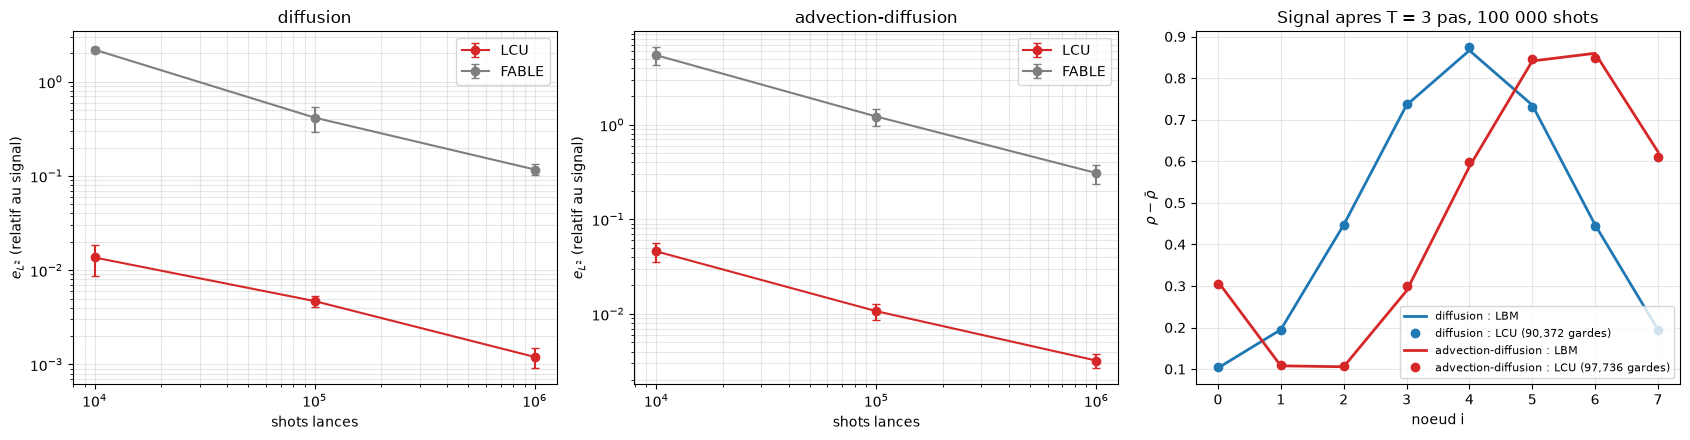

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
S_ = np.array(liste_shots)
for a_, m in zip(ax[:2], modeles):
    for meth, col in (("LCU", "tab:red"), ("FABLE", "tab:gray")):
        r = m["res"][meth]
        a_.errorbar(S_, np.nanmean(r["err"], 1), yerr=np.nanstd(r["err"], 1), fmt="o-", color=col, capsize=3, label=meth)
    a_.set_xscale("log"); a_.set_yscale("log"); a_.grid(alpha=0.3, which="both"); a_.legend()
    a_.set_xlabel("shots lances"); a_.set_ylabel(r"$e_{L^2}$ (relatif au signal)"); a_.set_title(m["nom"])
a_ = ax[2]; x = np.arange(N)
for m, col in zip(modeles, ("tab:blue", "tab:red")):
    P, garde = executer(m["qc_t"]["LCU"], 100_000, 7)
    f_rec = reconstruire_g(m, P/garde)
    a_.plot(x, m["signal"], "-", color=col, lw=2, label=f"{m['nom']} : LBM")
    a_.plot(x, f_rec.sum(0) - m["fond"], "o", color=col, label=f"{m['nom']} : LCU ({garde:,} gardes)")
a_.set_xlabel("noeud i"); a_.set_ylabel(r"$\rho-\bar\rho$"); a_.grid(alpha=0.3); a_.legend(fontsize=8)
a_.set_title(f"Signal apres T = {T} pas, 100 000 shots")
plt.tight_layout(); plt.show()

## 7. Tableau comparatif ($k=3$, $T=3$)

Coûts sur le circuit **transpilé** en `cx` + `u` (`optimization_level=1`), mesures retirées.

In [9]:
i6 = liste_shots.index(1_000_000)
print(f"{'':34s}{'diffusion':>22s}{'advection-diffusion':>24s}")
print(f"{'':34s}{'FABLE':>11s}{'LCU':>11s}{'FABLE':>12s}{'LCU':>12s}")
lignes = []
for m in modeles:
    cf = couts(m["qc_t"]["FABLE"].remove_final_measurements(inplace=False))
    cl = couts(m["qc_lcu"])
    m["cout"] = {"FABLE": cf, "LCU": cl}
def ligne(nom, f):
    vals = [f(m, meth) for m in modeles for meth in ("FABLE", "LCU")]
    print(f"{nom:34s}{vals[0]:>11s}{vals[1]:>11s}{vals[2]:>12s}{vals[3]:>12s}")
ligne("qubits", lambda m, me: str(m["cout"][me]["qubits"]))
ligne("CNOT", lambda m, me: str(m["cout"][me]["cx"]))
ligne("profondeur", lambda m, me: str(m["cout"][me]["depth"]))
ligne("ancillas par pas", lambda m, me: str(m["fab"].num_qubits - 2 if me == "FABLE" else 1))
ligne("succes cumule (mesure, 1M shots)", lambda m, me: f"{m['res'][me]['garde'][i6].mean()/1e6:.2e}")
ligne("e_L2 a 1M shots", lambda m, me: f"{np.nanmean(m['res'][me]['err'][i6]):.4f}")

                                               diffusion     advection-diffusion
                                        FABLE        LCU       FABLE         LCU
qubits                                     14          8          14           8
CNOT                                      934        888         934         910
profondeur                               1641       1539        1641        1591
ancillas par pas                            3          1           3           1
succes cumule (mesure, 1M shots)     2.28e-04   9.04e-01    2.53e-04    9.78e-01
e_L2 a 1M shots                        0.1170     0.0012      0.3085      0.0032


**Lecture.**
- **Succès** : c'est le gain principal, et il vient du **facteur 1** (changement de variables + LCU).
- **Précision à shots égaux** : elle en découle directement, puisqu'on garde environ 4 000 fois plus de *shots*.
- **Qubits** : 1 ancilla par pas au lieu de 3.
- **CNOT** : le gain est modeste, car le streaming par incréments ($3\times314$ CNOT pour $k=3$) domine le circuit ; la collision passe de 22 à 8 CNOT par pas. Voir la partie 8.

## 8. Portée du résultat

Ce qui suit mesure comment le circuit se comporte quand on augmente la taille du réseau ($N=2^k$) et le nombre de pas $T$.

### 8.1 Nombre de qubits : croissance linéaire en $T$

Chaque pas utilise une ancilla **neuve** (la mesure de toutes les ancillas se fait à la fin, principe de la mesure différée). Le nombre de qubits vaut donc
$$n_{qubits}=\underbrace{k}_{\text{position}}+\underbrace{2}_{\text{direction}}+\underbrace{T}_{\text{ancillas}}\qquad(\text{FABLE : }k+2+3T).$$
- croissance **logarithmique** en $N$ ($k=\log_2N$) : c'est l'atout de l'encodage par amplitudes ;
- croissance **linéaire** en $T$ : c'est la limite principale de cette implémentation. Pour $T=100$ pas, il faut 105 qubits avec $k=3$.

**Remède (non implémenté ici).** Mesurer l'ancilla à la fin de chaque pas, puis la réinitialiser (`reset`) : on passe à $k+3$ qubits quel que soit $T$, avec le même résultat. Cela demande un matériel qui supporte la mesure en cours de circuit.

In [10]:
Ts = [1, 3, 10, 30, 100]; ks = [3, 5, 10]
print(f"{'':12s}" + "".join(f"{'T = ' + str(t):>10s}" for t in Ts))
for k_ in ks:
    print(f"LCU   k={k_:<3d}" + "".join(f"{k_ + 2 + t:>10d}" for t in Ts))
for k_ in ks:
    print(f"FABLE k={k_:<3d}" + "".join(f"{k_ + 2 + 3*t:>10d}" for t in Ts))
print("\nverification sur les circuits construits (k = 3) :",
      [circuit_lcu(modeles[0], t, mesures=False).num_qubits for t in (1, 3, 5)], "pour T = 1, 3, 5")

                 T = 1     T = 3    T = 10    T = 30   T = 100
LCU   k=3           6         8        15        35       105
LCU   k=5           8        10        17        37       107
LCU   k=10         13        15        22        42       112
FABLE k=3           8        14        35        95       305
FABLE k=5          10        16        37        97       307
FABLE k=10         15        21        42       102       312

verification sur les circuits construits (k = 3) : [6, 8, 10] pour T = 1, 3, 5


### 8.2 Nombre de portes : le streaming domine

On mesure les CNOT (après transpilation) en séparant les trois blocs, pour $k=3$ à $6$ et $T=3$ :
- la **collision** coûte 8 CNOT par pas, **indépendamment de $N$** (elle n'agit que sur la direction et l'ancilla) ;
- la **préparation** croît avec $k$ ;
- le **streaming** par incréments croît le plus vite : c'est lui qui fixe le coût total.

  k modele                 prep  collision/pas  streaming/pas  CNOT total  profondeur
  3 diffusion                 8              8            314         888        1539
  3 advection-diffusion      30              8            314         910        1591
  4 diffusion                16              8            880        2560        4418
  4 advection-diffusion      62              8            880        2606        4526
  5 diffusion                32              8           2700        7640       13221
  5 advection-diffusion     126              8           2700        7734       13425
  6 diffusion                64              8           7796       22244       38446
  6 advection-diffusion     254              8           7796       22434       38842


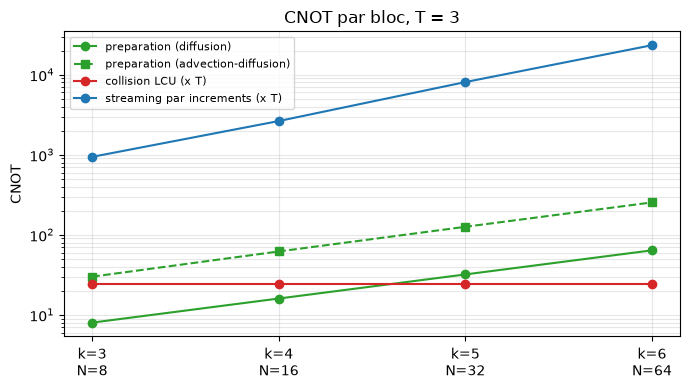

In [11]:
ks = [3, 4, 5, 6]; rows = []
for k_ in ks:
    for nom in ("diffusion", "advection-diffusion"):
        m_ = modele(nom, k_)
        c_prep = couts(preparation(m_))["cx"]
        c_coll = couts(collision_lcu(Wm @ m_["E"] @ Wp)[0])["cx"]
        c_str = couts(streaming(k_))["cx"]
        c_tot = couts(circuit_lcu(m_, T, mesures=False))
        rows.append((k_, nom, c_prep, c_coll, c_str, c_tot["cx"], c_tot["depth"]))
print(f"{'k':>3s} {'modele':20s}{'prep':>7s}{'collision/pas':>15s}{'streaming/pas':>15s}{'CNOT total':>12s}{'profondeur':>12s}")
for r in rows:
    print(f"{r[0]:>3d} {r[1]:20s}{r[2]:>7d}{r[3]:>15d}{r[4]:>15d}{r[5]:>12d}{r[6]:>12d}")

fig, ax = plt.subplots(figsize=(7, 4))
for nom, mk in (("diffusion", "o-"), ("advection-diffusion", "s--")):
    rr = [r for r in rows if r[1] == nom]
    ax.semilogy(ks, [r[2] for r in rr], mk, color="tab:green", label=f"preparation ({nom})")
ax.semilogy(ks, [T*r[3] for r in rows if r[1] == "diffusion"], "o-", color="tab:red", label="collision LCU (x T)")
ax.semilogy(ks, [T*r[4] for r in rows if r[1] == "diffusion"], "o-", color="tab:blue", label="streaming par increments (x T)")
ax.set_xticks(ks); ax.set_xticklabels([f"k={k_}\nN={2**k_}" for k_ in ks]); ax.set_ylabel("CNOT")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8); ax.set_title(f"CNOT par bloc, T = {T}")
plt.tight_layout(); plt.show()

### 8.3 Probabilité de succès aux temps longs

D'après la partie 5, $p_{tot}=\|G^T\|^2/\|G^0\|^2$ **exactement**. On peut donc la calculer classiquement pour de grands $T$ (ici $N=256$, sans construire le circuit).

**Diffusion, approximation (justifiée sous hypothèse).** Si le système reste proche de l'équilibre local, $G^n\approx\sqrt\omega\otimes\rho^n$, donc $\|G^n\|^2\approx\|\rho^n\|^2$ (car $\|\sqrt\omega\|=1$). Pour une gaussienne d'écart-type $s_n=\sqrt{\sigma_0^2+2Dn}$ et d'amplitude $\sigma_0/s_n$, on a $\|\rho^n\|^2\propto\sigma_0^2/s_n$, d'où
$$p_{tot}(T)\approx\frac{\sigma_0}{\sqrt{\sigma_0^2+2DT}},\qquad D=c_s^2\big(\tau-\tfrac12\big).$$
La décroissance est en $T^{-1/2}$, donc **polynomiale**, contre $(1/16)^T$ au mieux avec FABLE.

**Advection.** Le fond $\bar\rho$ est à l'équilibre et ne se dissipe pas ; il domine $\|G\|$, donc $p_{tot}$ reste proche de 1. Ce chiffre ne mesure donc pas la qualité de la simulation de la perturbation.

     T   diffusion   formule   advection    FABLE (1/16)^T
     1      1.0000    0.9583      1.0000           6.2e-02
     3      0.9035    0.8885      0.9982           2.4e-04
    10      0.7337    0.7276      0.9948           9.1e-13
    30      0.5238    0.5222      0.9906           7.5e-37
   100      0.3182    0.3180      0.9865          3.9e-121
   300      0.1902    0.1901      0.9840           0.0e+00
  1000      0.1055    0.1055      0.9823           0.0e+00
  2000      0.0748    0.0748      0.9817           0.0e+00


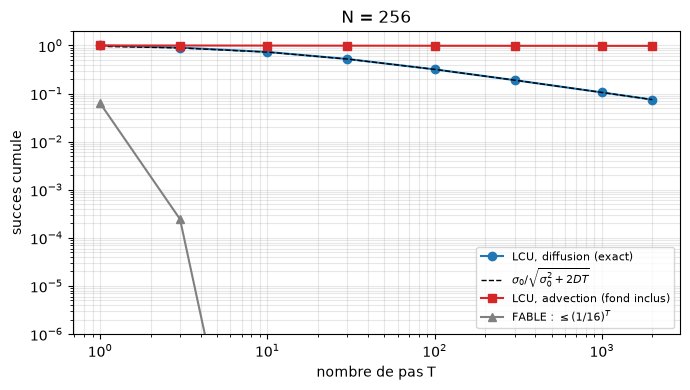

In [12]:
Nl = 256; kl = 8; Tmax = 2000; Tsel = [1, 3, 10, 30, 100, 300, 1000, 2000]
D_diff = cs2*(tau - 0.5)
res_T = {}
for nom in ("diffusion", "advection-diffusion"):
    m_ = modele(nom, kl); f = m_["f0"].copy(); n0 = np.sum((f/sq[:, None])**2); vals = []
    for t in range(1, Tmax + 1):
        f = lbm_step(f, m_["E"])
        if t in Tsel: vals.append(np.sum((f/sq[:, None])**2)/n0)
    res_T[nom] = np.array(vals)
formule = sigma0/np.sqrt(sigma0**2 + 2*D_diff*np.array(Tsel))
print(f"{'T':>6s}{'diffusion':>12s}{'formule':>10s}{'advection':>12s}{'FABLE (1/16)^T':>18s}")
for t, pd, fo, pa in zip(Tsel, res_T["diffusion"], formule, res_T["advection-diffusion"]):
    print(f"{t:>6d}{pd:>12.4f}{fo:>10.4f}{pa:>12.4f}{(1/16)**t:>18.1e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(Tsel, res_T["diffusion"], "o-", color="tab:blue", label="LCU, diffusion (exact)")
ax.loglog(Tsel, formule, "k--", lw=1, label=r"$\sigma_0/\sqrt{\sigma_0^2+2DT}$")
ax.loglog(Tsel, res_T["advection-diffusion"], "s-", color="tab:red", label="LCU, advection (fond inclus)")
ax.loglog(Tsel[:4], (1/16)**np.array(Tsel[:4]), "^-", color="gray", label=r"FABLE : $\leq(1/16)^T$")
ax.set_ylim(1e-6, 2); ax.set_xlabel("nombre de pas T"); ax.set_ylabel("succes cumule"); ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8); ax.set_title(f"N = {Nl}"); plt.tight_layout(); plt.show()

### 8.4 Lecture des résultats : le coût qui ne disparaît pas

Pour reconstruire **tout** le champ $\rho$, chaque population $f_{a,i}$ est estimée à partir de fréquences de mesure. L'erreur statistique décroît en $1/\sqrt{n_{gardes}}$ (vérifié en partie 6 : la pente est d'environ $-1/2$), et il y a $3N$ populations à estimer. Le nombre de *shots* nécessaire pour une précision donnée croît donc avec $N$.

Conséquence : **le gain obtenu porte sur la post-sélection et sur le circuit, pas sur la lecture.** Reconstruire le champ complet ne peut pas battre un LBM classique (coût $O(NT)$). Un avantage demanderait de ne mesurer que **quelques observables** (moments, amplitude d'un mode de Fourier), éventuellement avec une estimation d'amplitude.

### 8.5 Bilan

| Point | Résultat | Statut |
|---|---|---|
| Collision | bloc encodé $=\hat C_{loc}$ exactement, facteur 1, 1 ancilla, 8 CNOT par pas | démontré + vérifié |
| Équivalence avec le LBM | circuit $=$ LBM à la précision machine, diffusion et advection | vérifié |
| Succès | $p_{tot}=\|G^T\|^2/\|G^0\|^2$ ; $\approx0{,}90$ (diffusion) et $\approx0{,}98$ (advection) pour $T=3$ ; $\propto T^{-1/2}$ aux temps longs en diffusion | démontré + vérifié |
| Qubits | $k+2+T$ : logarithmique en $N$, **linéaire en $T$** | vérifié |
| Portes | dominées par le streaming par incréments, qui croît le plus vite avec $k$ | vérifié |
| Lecture du champ complet | nombre de *shots* croissant avec $N$ | conséquence de la loi en $1/\sqrt n$ |

**Conditions de validité**
- $\tau\ge\frac12$ : sinon $|\lambda|>1$, et les coefficients de la LCU ne sont plus positifs de somme 1.
- **Équilibre linéaire en $f$** : c'est le cas ici (diffusion, et advection à l'ordre 1 avec $u=j/\rho$). Un équilibre d'ordre 2 en $u$ (termes en $j^2/\rho$) n'est pas linéaire, et la méthode ne s'applique pas telle quelle.
- **Poids uniformes en espace** : si les poids dépendaient du nœud (vitesse imposée variable en espace), $\mathcal W$ ne commuterait plus avec $S$.
- $f\ge0$ pour la lecture par $\sqrt P$ : d'où le fond $\bar\rho$ en advection.
- **Conditions aux limites** : périodiques ici. Le changement de variables reste valable pour une permutation entre directions de même poids, comme le rebond en D1Q3 ($\omega_-=\omega_+$), mais ce cas n'est pas testé dans ce notebook.

**Pistes pour aller plus loin**
1. Réutiliser l'ancilla (mesure + `reset`) : $k+3$ qubits quel que soit $T$.
2. Streaming en base de Fourier : $S$ est circulant, donc diagonal après QFT sur la position, et la collision commute avec cette QFT. Cela réduit fortement le coût du streaming (périodique uniquement).
3. Amplification du succès pour les simulations longues en diffusion.
4. Lecture d'observables plutôt que du champ complet.